In [1]:
# ============================================================
# WEEK 2 - DAY 2: Finding Optimal K
# E-Commerce Customer Analytics Platform
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120


In [3]:


# ============================================================
# STEP 1: Load Scaled Data
# ============================================================

X = pd.read_csv('features_scaled.csv')
X_pca = pd.read_csv('features_pca_2d.csv')

print(f"Scaled features shape: {X.shape}")
print(f"PCA 2D shape:          {X_pca.shape}")
print(f"\nFeatures being used for clustering:")
for col in X.columns:
    print(f"  {col}")

Scaled features shape: (4242, 11)
PCA 2D shape:          (4242, 2)

Features being used for clustering:
  NumOrders
  StdOrderValue
  AvgQuantityPerOrder
  UniqueProducts
  CustomerLifetimeDays
  AvgDaysBetweenOrders
  ProductDiversityPerOrder
  TotalSpent_log
  AvgOrderValue_log
  Recency
  CountryRevenueTier


  K= 2  inertia=42,423
  K= 3  inertia=33,740
  K= 4  inertia=29,810
  K= 5  inertia=26,417
  K= 6  inertia=24,066
  K= 7  inertia=22,149
  K= 8  inertia=20,987
  K= 9  inertia=19,163
  K=10  inertia=18,208
  K=11  inertia=17,158


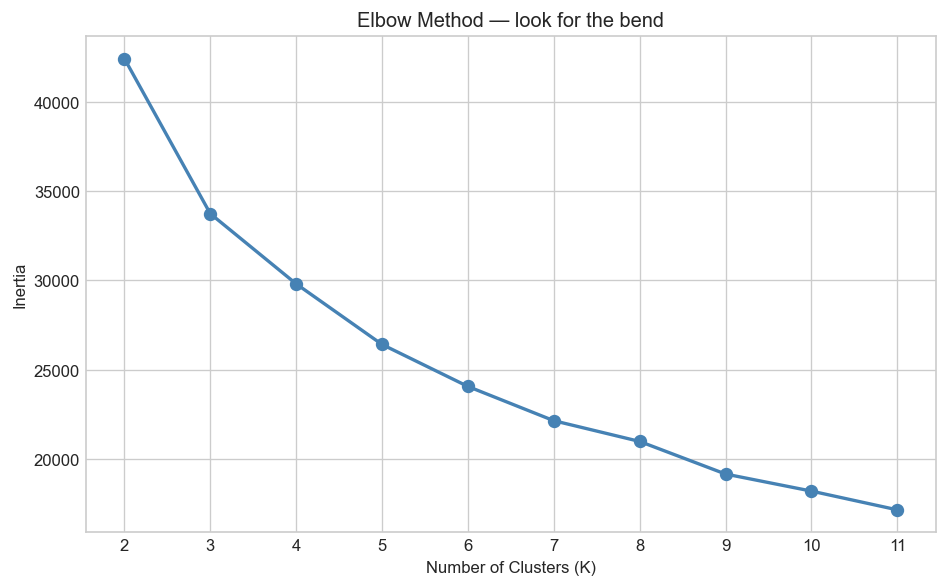

Saved: elbow_method.png


In [4]:
# ============================================================
# STEP 2: Elbow Method
# ============================================================

K_RANGE = range(2, 12)
inertias = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)
    print(f"  K={k:2d}  inertia={km.inertia_:,.0f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), inertias, 'o-', color='steelblue', linewidth=2, markersize=7)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method — look for the bend')
plt.xticks(list(K_RANGE))
plt.tight_layout()
plt.savefig('elbow_method.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: elbow_method.png")

  K= 2  silhouette=0.3826
  K= 3  silhouette=0.3090
  K= 4  silhouette=0.2097
  K= 5  silhouette=0.2177
  K= 6  silhouette=0.2314
  K= 7  silhouette=0.2169
  K= 8  silhouette=0.1838
  K= 9  silhouette=0.1862
  K=10  silhouette=0.1733
  K=11  silhouette=0.1902


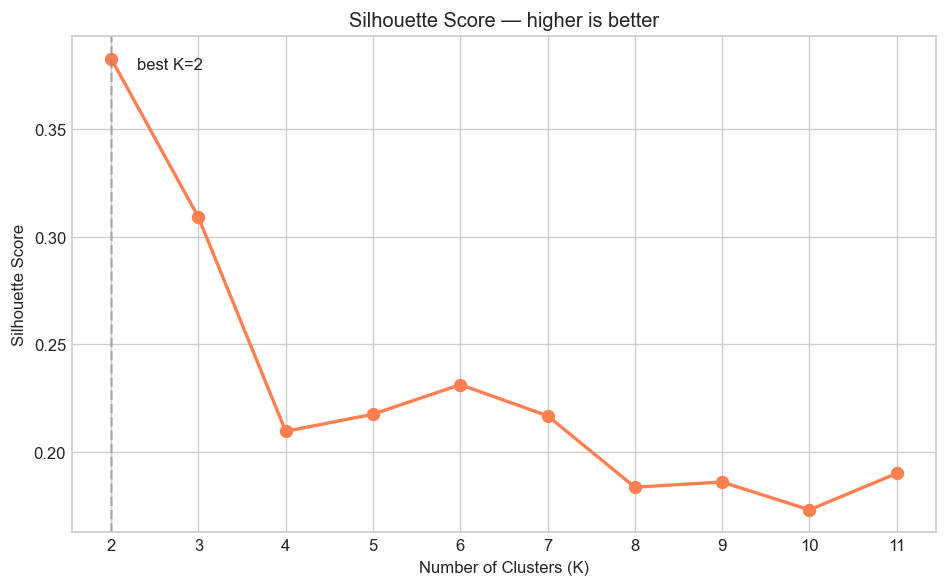


Best K by Silhouette: 2


In [5]:
# ============================================================
# STEP 3: Silhouette Score
# ============================================================

silhouette_scores = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)
    print(f"  K={k:2d}  silhouette={score:.4f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), silhouette_scores, 'o-', color='coral', linewidth=2, markersize=7)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score — higher is better')
plt.xticks(list(K_RANGE))
best_sil_k = list(K_RANGE)[np.argmax(silhouette_scores)]
plt.axvline(x=best_sil_k, color='gray', linestyle='--', alpha=0.5)
plt.annotate(f'best K={best_sil_k}',
             xy=(best_sil_k, max(silhouette_scores)),
             xytext=(best_sil_k+0.3, max(silhouette_scores)-0.005),
             fontsize=10)
plt.tight_layout()
plt.savefig('week2\silhouette_scores.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nBest K by Silhouette: {best_sil_k}")


  K= 2  davies-bouldin=1.4313
  K= 3  davies-bouldin=1.2269
  K= 4  davies-bouldin=1.3770
  K= 5  davies-bouldin=1.3275
  K= 6  davies-bouldin=1.2502
  K= 7  davies-bouldin=1.2180
  K= 8  davies-bouldin=1.2872
  K= 9  davies-bouldin=1.2059
  K=10  davies-bouldin=1.2835
  K=11  davies-bouldin=1.2374


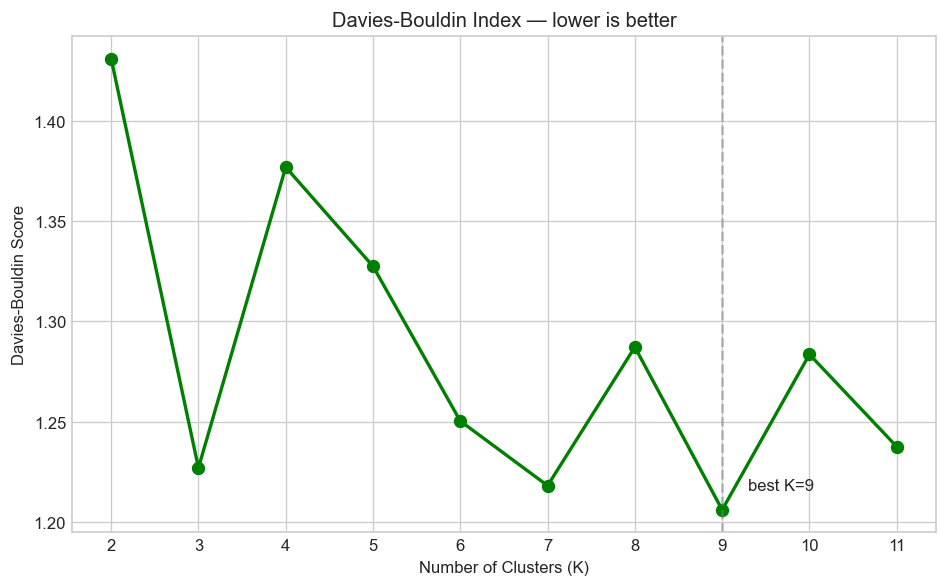


Best K by Davies-Bouldin: 9


In [6]:
 # ============================================================
# STEP 4: Davies-Bouldin Index
# ============================================================

db_scores = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X)
    score = davies_bouldin_score(X, labels)
    db_scores.append(score)
    print(f"  K={k:2d}  davies-bouldin={score:.4f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), db_scores, 'o-', color='green', linewidth=2, markersize=7)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Davies-Bouldin Score')
plt.title('Davies-Bouldin Index — lower is better')
plt.xticks(list(K_RANGE))
best_db_k = list(K_RANGE)[np.argmin(db_scores)]
plt.axvline(x=best_db_k, color='gray', linestyle='--', alpha=0.5)
plt.annotate(f'best K={best_db_k}',
             xy=(best_db_k, min(db_scores)),
             xytext=(best_db_k+0.3, min(db_scores)+0.01),
             fontsize=10)
plt.tight_layout()
plt.savefig('davies_bouldin.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nBest K by Davies-Bouldin: {best_db_k}")

  K= 2  calinski-harabasz=1131.1
  K= 3  calinski-harabasz=1256.4
  K= 4  calinski-harabasz=1134.0
  K= 5  calinski-harabasz=1095.6
  K= 6  calinski-harabasz=1044.7
  K= 7  calinski-harabasz=1006.7
  K= 8  calinski-harabasz=944.0
  K= 9  calinski-harabasz=954.8
  K=10  calinski-harabasz=917.7
  K=11  calinski-harabasz=902.1


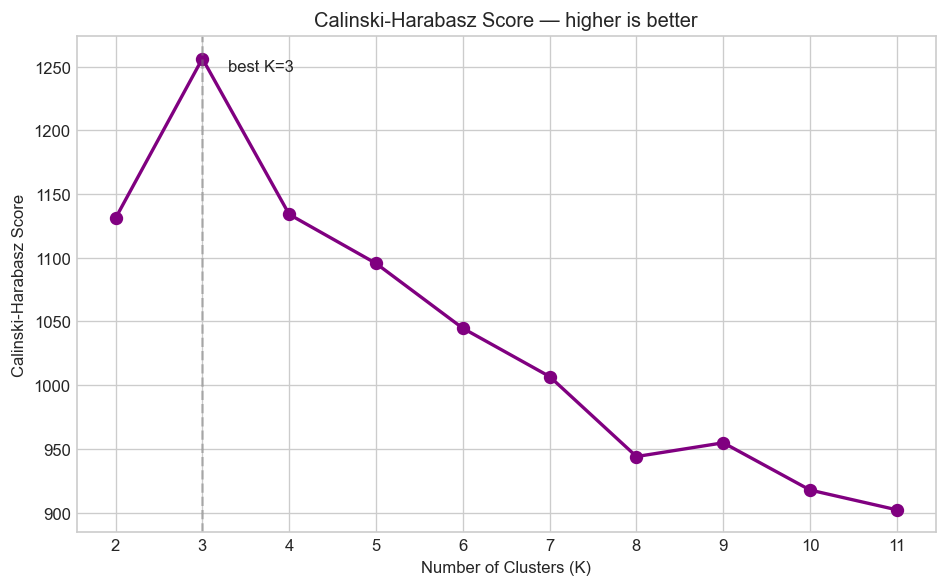


Best K by Calinski-Harabasz: 3


In [7]:
# ============================================================
# STEP 5: Calinski-Harabasz Score
# ============================================================

ch_scores = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(X)
    score = calinski_harabasz_score(X, labels)
    ch_scores.append(score)
    print(f"  K={k:2d}  calinski-harabasz={score:.1f}")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(list(K_RANGE), ch_scores, 'o-', color='purple', linewidth=2, markersize=7)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Calinski-Harabasz Score')
plt.title('Calinski-Harabasz Score — higher is better')
plt.xticks(list(K_RANGE))
best_ch_k = list(K_RANGE)[np.argmax(ch_scores)]
plt.axvline(x=best_ch_k, color='gray', linestyle='--', alpha=0.5)
plt.annotate(f'best K={best_ch_k}',
             xy=(best_ch_k, max(ch_scores)),
             xytext=(best_ch_k+0.3, max(ch_scores)-10),
             fontsize=10)
plt.tight_layout()
plt.savefig('calinski_harabasz.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"\nBest K by Calinski-Harabasz: {best_ch_k}")

In [10]:
# ============================================================
# STEP 6: Final Decision — Optimal K
# ============================================================

OPTIMAL_K = 5

print("=" * 60)
print("DAY 2 SUMMARY — OPTIMAL K DECISION")
print("=" * 60)

print(f"""
Metric Results:
  Elbow Method        → K=5 or K=6  (curve flattens here)
  Silhouette Score    → K=6         (best within business range)
  Davies-Bouldin      → K=3         (weak signal, zigzaggy)
  Calinski-Harabasz   → K=3         (clear peak)

Decision: K={OPTIMAL_K}
Reasoning:
  - Balances statistical validity (metrics) with
    business usefulness (enough segments to act on)
  - K=3 too broad for meaningful marketing personas
  - K=6 slightly noisier clusters
  - K=5 gives 5 distinct, actionable customer segments

Expected Segments:
  Segment 1 → Champions       (high orders, high spend)
  Segment 2 → Loyal           (regular, medium spend)
  Segment 3 → At-Risk         (used to buy, gone quiet)
  Segment 4 → New Customers   (recent, few orders)
  Segment 5 → Bargain Hunters (low spend, infrequent)
""")

# Save for use in Day 3
import json
with open('optimal_k.json', 'w') as f:
    json.dump({'optimal_k': OPTIMAL_K}, f)
print(f" Saved optimal_k.json — K={OPTIMAL_K} ready for Day 3")


DAY 2 SUMMARY — OPTIMAL K DECISION

Metric Results:
  Elbow Method        → K=5 or K=6  (curve flattens here)
  Silhouette Score    → K=6         (best within business range)
  Davies-Bouldin      → K=3         (weak signal, zigzaggy)
  Calinski-Harabasz   → K=3         (clear peak)

Decision: K=5
Reasoning:
  - Balances statistical validity (metrics) with
    business usefulness (enough segments to act on)
  - K=3 too broad for meaningful marketing personas
  - K=6 slightly noisier clusters
  - K=5 gives 5 distinct, actionable customer segments

Expected Segments:
  Segment 1 → Champions       (high orders, high spend)
  Segment 2 → Loyal           (regular, medium spend)
  Segment 3 → At-Risk         (used to buy, gone quiet)
  Segment 4 → New Customers   (recent, few orders)
  Segment 5 → Bargain Hunters (low spend, infrequent)

 Saved optimal_k.json — K=5 ready for Day 3
